In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
import scipy as scipy
import seaborn as sns

# The data

In [2]:
from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer()

In [3]:
print("The keys of the object: {}".format(cancer.keys()))

The keys of the object: dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


Data description

In [4]:
print(cancer['DESCR'][:3000])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

Divide the data into training and test

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, stratify=cancer.target, random_state=42)

## Learn and evaluate the model

In [6]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

Making predictions for a single instance

In [7]:
pd.DataFrame([X_test[0,:]], columns=cancer.feature_names)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,12.75,16.7,82.51,493.8,0.1125,0.1117,0.0388,0.02995,0.212,0.06623,...,14.45,21.74,93.63,624.1,0.1475,0.1979,0.1423,0.08045,0.3071,0.08557


In [8]:
print("Predicted class probabilities tree: {}".format(tree.predict_proba([X_test[0,:]])))

Predicted class probabilities tree: [[0. 1.]]


In [9]:
print("Accuracy on test set: {:.3f}".format(tree.score(X_test, y_test)))

Accuracy on test set: 0.923


##  Inspecting and analyzing the model

### Feature importance

In [10]:
print("Feature importances:\n{}".format(tree.feature_importances_))

Feature importances:
[0.00752597 0.         0.         0.         0.         0.
 0.00668975 0.01354675 0.         0.         0.         0.04630969
 0.         0.01206867 0.00238745 0.         0.         0.
 0.         0.         0.69546322 0.06135808 0.         0.00903116
 0.         0.         0.01740312 0.11684357 0.01137258 0.        ]


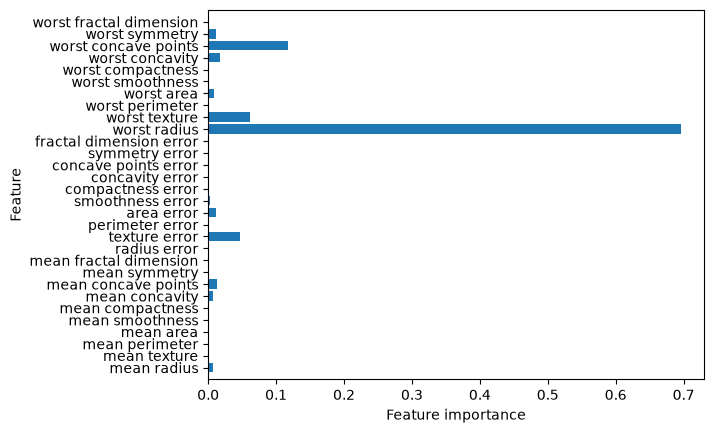

In [11]:
def plot_feature_importances_cancer(model):
    n_features = cancer.data.shape[1]
    plt.barh(range(n_features), model.feature_importances_, align='center')
    plt.yticks(np.arange(n_features), cancer.feature_names)
    plt.xlabel("Feature importance")
    plt.ylabel("Feature")
    plt.ylim(-1, n_features)

plot_feature_importances_cancer(tree)

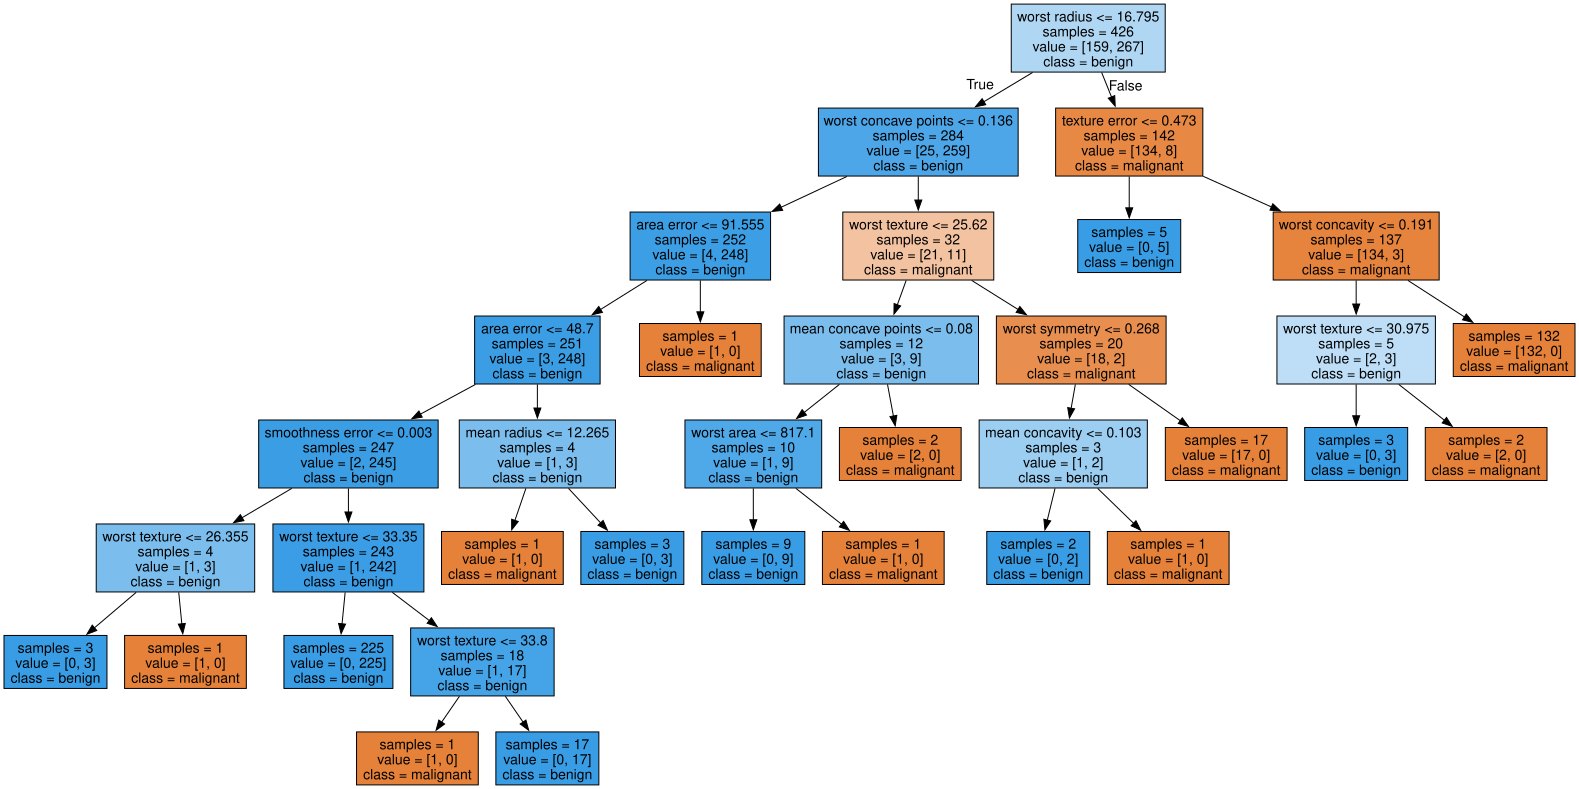

In [12]:
from sklearn.tree import export_graphviz
import graphviz
export_graphviz(tree, out_file="tree.dot", class_names=["malignant", "benign"],
                feature_names=cancer.feature_names, impurity=False, filled=True)

with open("tree.dot") as f:
    dot_graph = f.read()
display(graphviz.Source(dot_graph))

## Controlling model size

The tree built above is relatively complex with all leaves being pure or close to pure. This also means that the tree will perform well on instances it has seen before, but not so well on new instances (it does a poor job at generalizing). We can see this by comparing the score on the training data and the test data.

In [13]:
print("Accuracy on test data: {}".format(tree.score(X_test, y_test)))
print("Accuracy on training data: {}".format(tree.score(X_train, y_train)))

Accuracy on test data: 0.9230769230769231
Accuracy on training data: 1.0


One way to mitigate this effect is to control the size of the decision tree so that it does not become overly complex. We can do this by specifying:
* max_depth
* min_samples_split
* min_samples_leaf 

In [14]:
tree = DecisionTreeClassifier(min_samples_split=25, random_state=42)
tree.fit(X_train, y_train)
print("Accuracy on test data: {}".format(tree.score(X_test, y_test)))
print("Accuracy on training data: {}".format(tree.score(X_train, y_train)))

Accuracy on test data: 0.9440559440559441
Accuracy on training data: 0.9765258215962441


### Displaying the newly learned model

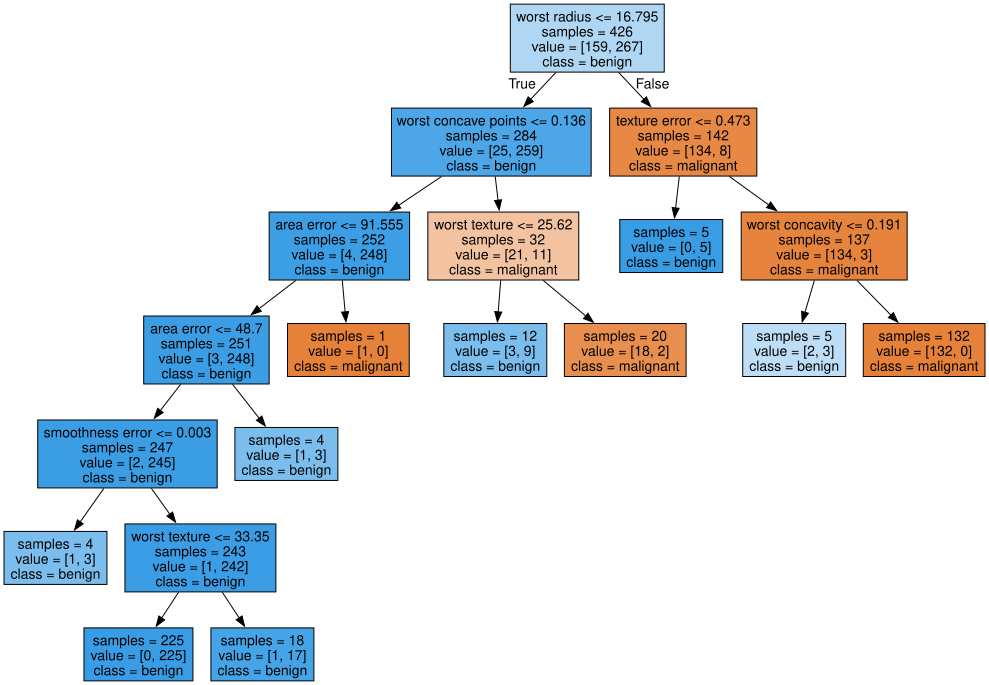

In [15]:
export_graphviz(tree, out_file="tree.dot", class_names=["malignant", "benign"],
                feature_names=cancer.feature_names, impurity=False, filled=True)

with open("tree.dot") as f:
    dot_graph = f.read()
display(graphviz.Source(dot_graph))

# Encoding categorical variables

### The data from the slides

In [16]:
df = pd.read_csv('DT-toy.csv')
X = df.iloc[:,0:-1].values
y = df.iloc[:,-1].values
display(df)

,Outlook,Temp,Humidity,Wind,Target
0,sunny,hot,high,weak,no
1,sunny,hot,high,strong,no
2,overcast,hot,high,weak,yes
3,rain,mild,high,weak,yes
4,rain,cool,normal,weak,yes
5,rain,cool,normal,strong,no
6,overcast,cool,normal,strong,yes
7,sunny,mild,high,weak,no
8,sunny,cool,normal,weak,yes
9,rain,mild,normal,weak,yes


Unfortunately, `sklearn` does not currently support categorical feature variables, but only numerical features. We therefore need to massage the data to get it into our framework. Specifically, we will make a so-called *one-hot encoding* of each of the variables.
* Example: The `Outlook` variable is transformed into three binary variables that can either be `true` or `false`:
    - `Outlook=overcast`
    - `Outlook=rain`
    - `Outlook=sunny`

In [17]:
# First we separate the data into features and target
df_feature_data = df.iloc[:,:-1]
df_target_data = df.iloc[:,-1]

# Next make an equivalent dictionary representation of the data over the features
dic = df_feature_data.T.to_dict().values()
print(dic)

dict_values([{'Outlook': 'sunny', 'Temp': 'hot', 'Humidity': 'high', 'Wind': 'weak'}, {'Outlook': 'sunny', 'Temp': 'hot', 'Humidity': 'high', 'Wind': 'strong'}, {'Outlook': 'overcast', 'Temp': 'hot', 'Humidity': 'high', 'Wind': 'weak'}, {'Outlook': 'rain', 'Temp': 'mild', 'Humidity': 'high', 'Wind': 'weak'}, {'Outlook': 'rain', 'Temp': 'cool', 'Humidity': 'normal', 'Wind': 'weak'}, {'Outlook': 'rain', 'Temp': 'cool', 'Humidity': 'normal', 'Wind': 'strong'}, {'Outlook': 'overcast', 'Temp': 'cool', 'Humidity': 'normal', 'Wind': 'strong'}, {'Outlook': 'sunny', 'Temp': 'mild', 'Humidity': 'high', 'Wind': 'weak'}, {'Outlook': 'sunny', 'Temp': 'cool', 'Humidity': 'normal', 'Wind': 'weak'}, {'Outlook': 'rain', 'Temp': 'mild', 'Humidity': 'normal', 'Wind': 'weak'}, {'Outlook': 'sunny', 'Temp': 'mild', 'Humidity': 'normal', 'Wind': 'strong'}, {'Outlook': 'overcast', 'Temp': 'mild', 'Humidity': 'high', 'Wind': 'strong'}, {'Outlook': 'overcast', 'Temp': 'hot', 'Humidity': 'normal', 'Wind': 'weak'

### First the data over the feature variables

Using `sklearn`'s `DictVectorizer` we can convert this data to a one-hot-encoded form 

In [18]:
from sklearn.feature_extraction import DictVectorizer
vec = DictVectorizer()
vec_data = vec.fit_transform(dic).toarray()
print("The newly constructed features:\n")
print(vec.feature_names_)
print("The associated binary data:\n")
print(vec_data)

The newly constructed features:

['Humidity=high', 'Humidity=normal', 'Outlook=overcast', 'Outlook=rain', 'Outlook=sunny', 'Temp=cool', 'Temp=hot', 'Temp=mild', 'Wind=strong', 'Wind=weak']
The associated binary data:

[[1. 0. 0. 0. 1. 0. 1. 0. 0. 1.]
 [1. 0. 0. 0. 1. 0. 1. 0. 1. 0.]
 [1. 0. 1. 0. 0. 0. 1. 0. 0. 1.]
 [1. 0. 0. 1. 0. 0. 0. 1. 0. 1.]
 [0. 1. 0. 1. 0. 1. 0. 0. 0. 1.]
 [0. 1. 0. 1. 0. 1. 0. 0. 1. 0.]
 [0. 1. 1. 0. 0. 1. 0. 0. 1. 0.]
 [1. 0. 0. 0. 1. 0. 0. 1. 0. 1.]
 [0. 1. 0. 0. 1. 1. 0. 0. 0. 1.]
 [0. 1. 0. 1. 0. 0. 0. 1. 0. 1.]
 [0. 1. 0. 0. 1. 0. 0. 1. 1. 0.]
 [1. 0. 1. 0. 0. 0. 0. 1. 1. 0.]
 [0. 1. 1. 0. 0. 0. 1. 0. 0. 1.]
 [1. 0. 0. 1. 0. 0. 0. 1. 1. 0.]]


### Next the target variable

This is much simpler

In [19]:
df_target_data.replace('yes','1',inplace=True)
df_target_data.replace('no','0',inplace=True)
df_target_data

0     0
1     0
2     1
3     1
4     1
5     0
6     1
7     0
8     1
9     1
10    1
11    1
12    1
13    0
Name: Target , dtype: str

## Now we are finally ready to learn a model

In [20]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(random_state=42, criterion="entropy")
tree.fit(vec_data, df_target_data.values)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samp

And get some insights by visualizing it ...

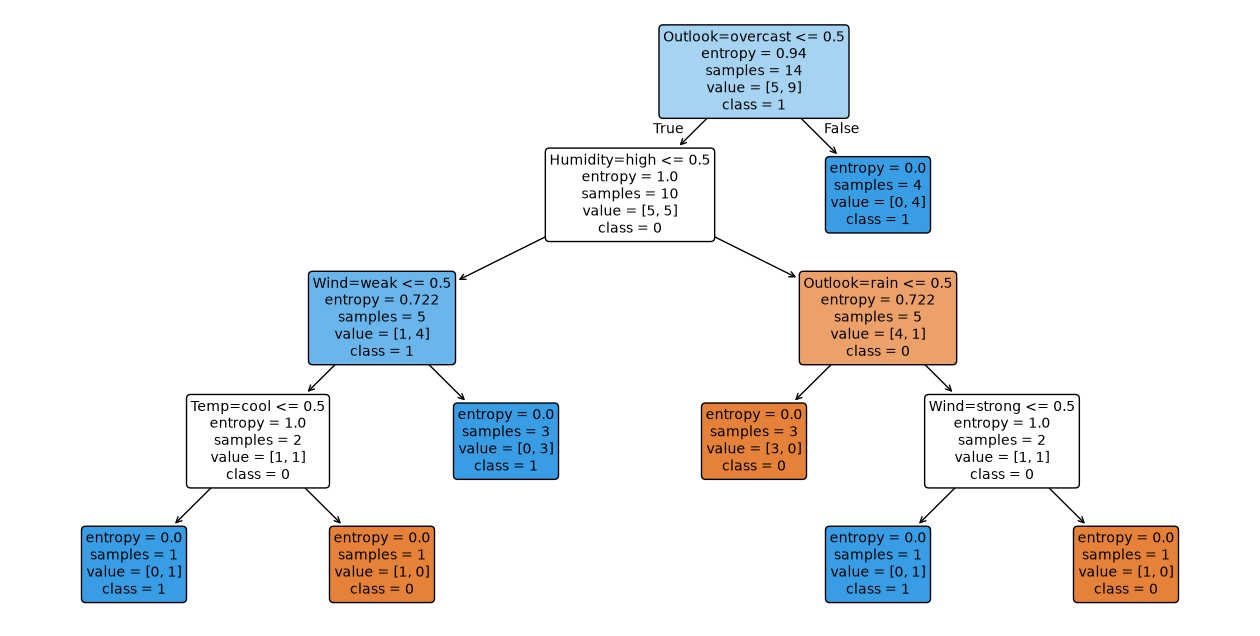

In [21]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Train a decision tree

# Visualize
plt.figure(figsize=(16, 8))
plot_tree(
    tree,
#    feature_names=["Feature 1", "Feature 2"],
    feature_names=vec.feature_names_,
    class_names=[str(c) for c in tree.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()

Alternatively using graphviz

In [22]:
from sklearn.tree import export_graphviz
export_graphviz(tree, out_file="tree.dot", class_names=["no", "yes"],
                feature_names=vec.feature_names_, impurity=False, filled=True)

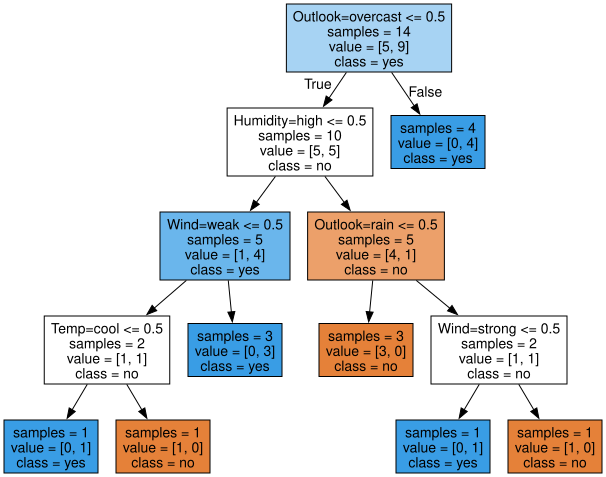

In [23]:
import graphviz

with open("tree.dot") as f:
    dot_graph = f.read()
display(graphviz.Source(dot_graph))